##1.Set Up

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SEED = 42
tf.keras.utils.set_random_seed(SEED)

from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

PROCESSED = ROOT / "ml" / "processed"
MODEL_DIR = ROOT / "ml" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Preprocessing config + dataset table
config = json.loads((PROCESSED / "preprocess_config.json").read_text())
df = pd.read_csv(PROCESSED / "dataset_splits.csv")

IMG_SIZE       = tuple(config["img_size"])          # (width, height) - must be square
BATCH_SIZE     = config["batch_size"]
MEAN           = np.array(config["mean"], dtype=np.float32)
STD            = np.array(config["std"], dtype=np.float32)
MASK_THRESHOLD = config["mask_threshold"]

gpus = tf.config.list_physical_devices('GPU')
print("Project root:", ROOT)
print("TensorFlow:", tf.__version__)
print("GPU Devices:", gpus if gpus else "None (Running on CPU)")
print("Image size:", IMG_SIZE, "| Batch size:", BATCH_SIZE)
print("Splits:", df["split"].value_counts().to_dict())


Project root: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
TensorFlow: 2.21.0
GPU Devices: None (Running on CPU)
Image size: (256, 256) | Batch size: 8
Splits: {'train': 6455, 'test': 808, 'val': 807}


## 2. Train / validation / test split

In [2]:
train_df = df[df["split"] == "train"].sample(n=min(1600, (df["split"] == "train").sum()), random_state=SEED).reset_index(drop=True)
val_df   = df[df["split"] == "val"].sample(n=min(200, (df["split"] == "val").sum()), random_state=SEED).reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)   # full test set

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 1600 | Val: 200 | Test: 808


## 3. Data loader

In [3]:
class SARDataLoader(tf.keras.utils.Sequence):
    def __init__(self, dataframe, batch_size=8, shuffle=False, augment=False, seed=42, **kwargs):
        super().__init__(**kwargs)
        self.data = dataframe.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.data))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.data) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __getitem__(self, index):
        batch = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        images, masks = [], []

        for i in batch:
            row = self.data.iloc[i]

            with Image.open(ROOT / row["image_path"]) as img:
                x = np.asarray(img.convert("RGB").resize(IMG_SIZE, Image.Resampling.BILINEAR), dtype=np.float32) / 255.0

            with Image.open(ROOT / row["mask_path"]) as m:
                y = (np.asarray(m.convert("L").resize(IMG_SIZE, Image.Resampling.NEAREST)) > MASK_THRESHOLD)
                y = y.astype(np.float32)[..., None]

            if self.augment:                      # random flips + 90° rotation
                if self.rng.random() < 0.5: x, y = x[:, ::-1], y[:, ::-1]
                if self.rng.random() < 0.5: x, y = x[::-1], y[::-1]
                k = int(self.rng.integers(4))
                x, y = np.rot90(x, k), np.rot90(y, k)

            images.append((x - MEAN) / STD)       # normalize
            masks.append(y)

        return np.stack(images).astype(np.float32), np.stack(masks).astype(np.float32)


train_loader = SARDataLoader(train_df, BATCH_SIZE, shuffle=True, augment=True, seed=SEED)
val_loader   = SARDataLoader(val_df,   BATCH_SIZE)
test_loader  = SARDataLoader(test_df,  BATCH_SIZE)

X, Y = train_loader[0]
print("Images:", X.shape, "| Masks:", Y.shape, "| Mask values:", np.unique(Y))
print("Batches -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Images: (8, 256, 256, 3) | Masks: (8, 256, 256, 1) | Mask values: [0. 1.]
Batches -> train: 200 | val: 25 | test: 101


## 4. Metrics and loss

In [4]:
def dice_score(y_true, y_pred, eps=1e-6):
    y_true, y_pred = tf.cast(y_true, tf.float32), tf.cast(y_pred, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    total = tf.reduce_sum(y_true + y_pred, axis=[1, 2, 3])
    return tf.reduce_mean((2 * inter + eps) / (total + eps))


def iou_score(y_true, y_pred, eps=1e-6):
    y_true, y_pred = tf.cast(y_true, tf.float32), tf.cast(y_pred, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true + y_pred - y_true * y_pred, axis=[1, 2, 3])
    return tf.reduce_mean((inter + eps) / (union + eps))


def combined_loss(y_true, y_pred):
    """Binary cross-entropy + Dice loss (good for small foreground areas)."""
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - dice_score(y_true, y_pred))

## 5. Model

In [5]:
def conv(x, filters, n=2):
    for _ in range(n):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x


def build_basic_cnn(input_shape):
    inputs = layers.Input(shape=input_shape)

    x = conv(inputs, 16);  x = layers.MaxPooling2D(2)(x)     # encoder
    x = conv(x, 32);       x = layers.MaxPooling2D(2)(x)
    x = conv(x, 64)                                          # bottleneck

    x = layers.UpSampling2D(2)(x);  x = conv(x, 32, n=1)     # decoder
    x = layers.UpSampling2D(2)(x);  x = conv(x, 16, n=1)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(x)  # binary mask
    return Model(inputs, outputs, name="Basic_CNN_Segmentation")


model = build_basic_cnn((IMG_SIZE[1], IMG_SIZE[0], 3))
model.summary()

Model: "Basic_CNN_Segmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 256, 256, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 256, 256, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,185 (371.82 KB)

 Trainable params: 95,185 (371.82 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile and callbacks

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=combined_loss,
    metrics=[dice_score, iou_score],
)

callbacks = [
    ModelCheckpoint(str(MODEL_DIR / "best_cnn.keras"), monitor="val_dice_score", mode="max", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_dice_score", mode="max", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

## 7. Train

In [7]:
history = model.fit(train_loader, validation_data=val_loader, epochs=15, callbacks=callbacks)

Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - dice_score: 0.4982 - iou_score: 0.3698 - loss: 0.9075
Epoch 1: val_dice_score improved from None to 0.55891, saving model to C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\best_cnn.keras

Epoch 1: finished saving model to C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\best_cnn.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - dice_score: 0.5576 - iou_score: 0.4251 - loss: 0.7971 - val_dice_score: 0.5589 - val_iou_score: 0.4175 - val_loss: 0.7377 - learning_rate: 0.0010
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - dice_score: 0.6138 - iou_score: 0.4769 - loss: 0.6816
Epoch 2: val_dice_score improved from 0.55891 to 0.63409, saving model to C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\best_cnn.keras

Epoch 2: finished saving model to C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\best_cnn.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 26s 128ms/st

## 8. Training curves

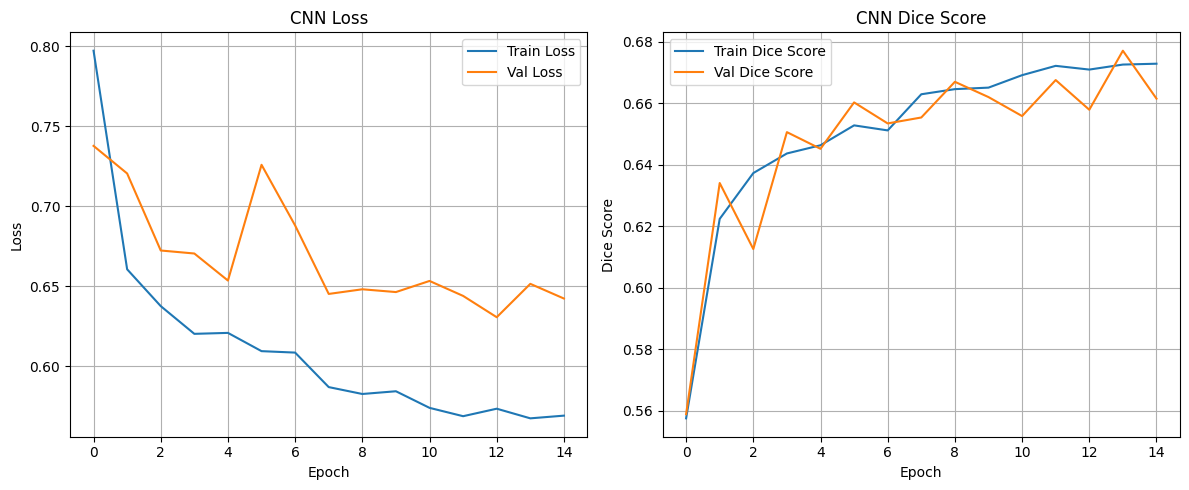

In [8]:
plt.figure(figsize=(12, 5))
for i, (name, key) in enumerate([("Loss", "loss"), ("Dice Score", "dice_score")], 1):
    plt.subplot(1, 2, i)
    plt.plot(history.history[key], label=f"Train {name}")
    plt.plot(history.history[f"val_{key}"], label=f"Val {name}")
    plt.xlabel("Epoch"); plt.ylabel(name); plt.title(f"CNN {name}")
    plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

## 9. Evaluate on the full test set

In [9]:
# Keras metrics (best weights are already restored by EarlyStopping)
results = model.evaluate(test_loader, return_dict=True, verbose=0)
print("Keras test results:", {k: round(float(v), 4) for k, v in results.items()})

# Per-image metrics at threshold 0.5
probs = model.predict(test_loader, verbose=0)
pred  = probs > 0.5
true  = np.concatenate([test_loader[i][1] for i in range(len(test_loader))]) > 0.5

axes  = (1, 2, 3)
inter = (pred & true).sum(axes)
p_sum, t_sum = pred.sum(axes), true.sum(axes)
union = p_sum + t_sum - inter
empty = (p_sum + t_sum) == 0

dice      = np.where(empty, 1.0, 2 * inter / np.maximum(p_sum + t_sum, 1))
iou       = np.where(union == 0, 1.0, inter / np.maximum(union, 1))
precision = inter / np.maximum(p_sum, 1)
recall    = inter / np.maximum(t_sum, 1)

print("\nCNN Macro Test Metrics")
for name, val in [("Dice", dice), ("IoU", iou), ("Precision", precision), ("Recall", recall)]:
    print(f"{name:10s}: {val.mean():.4f}")

Keras test results: {'dice_score': 0.6799, 'iou_score': 0.5575, 'loss': 0.6665}

CNN Macro Test Metrics
Dice      : 0.7355
IoU       : 0.6252
Precision : 0.7273
Recall    : 0.8095


## 10. Sample predictions

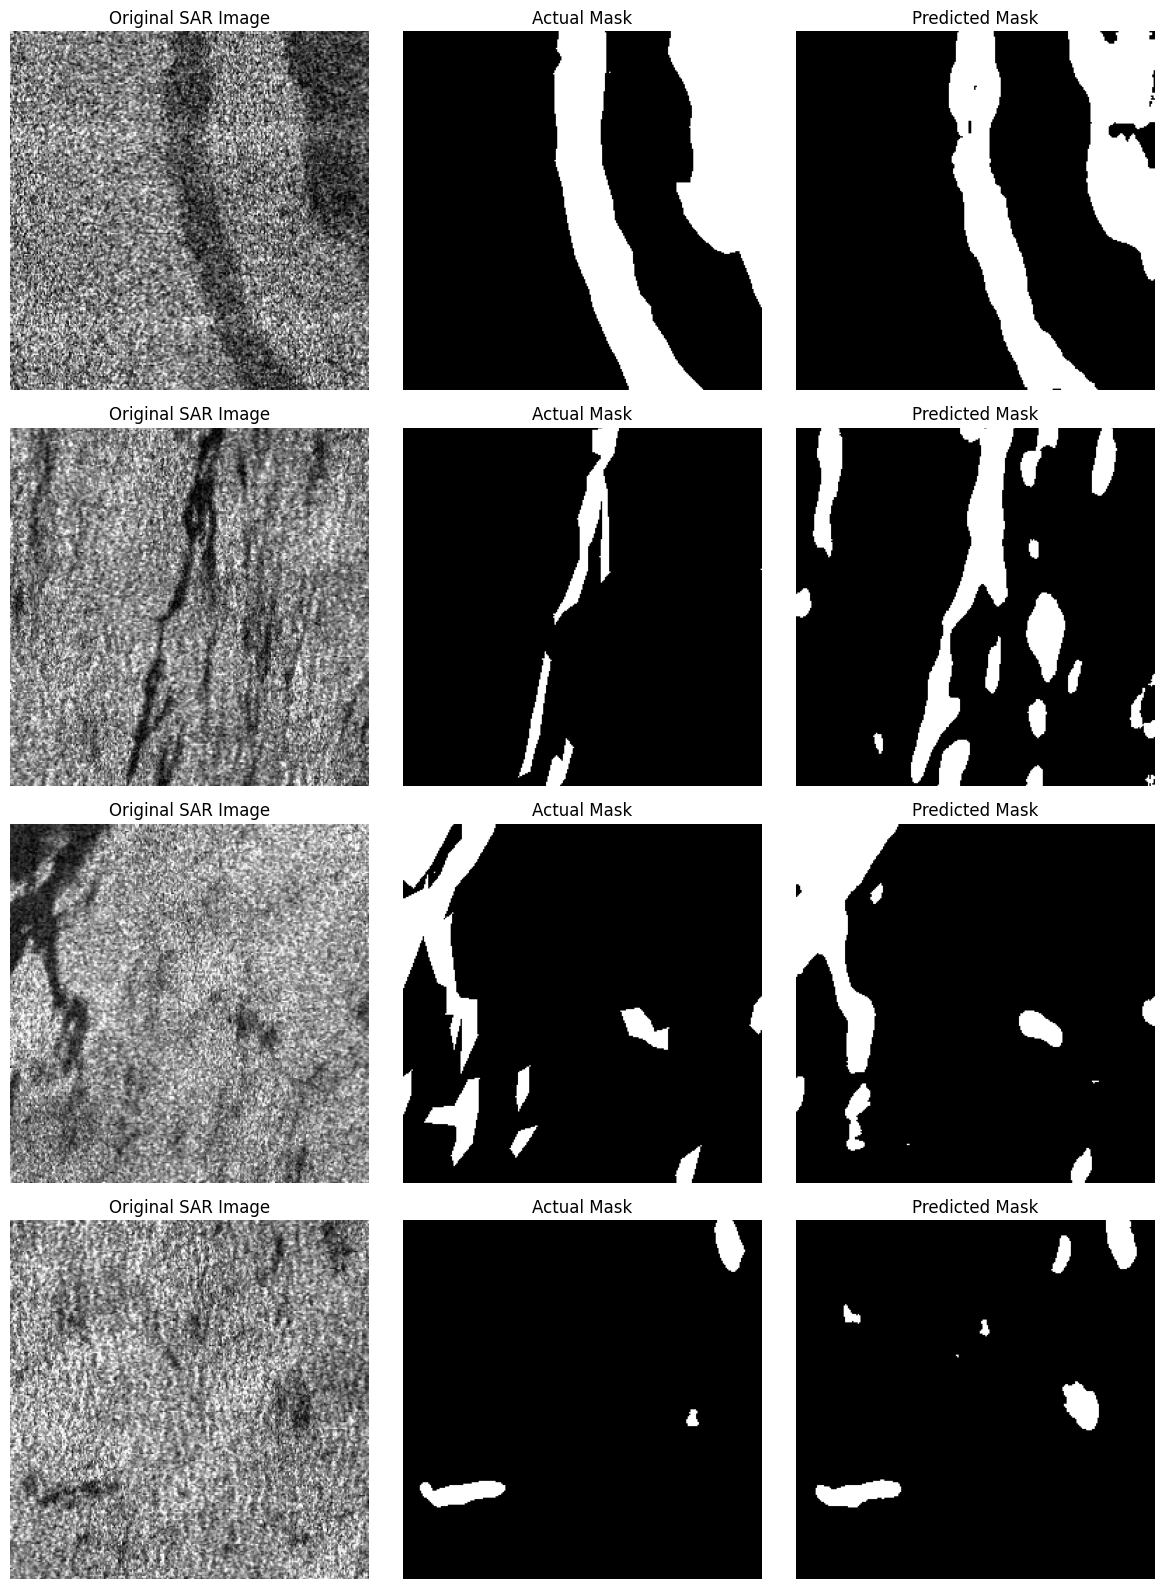

In [10]:
X, Y = test_loader[0]
n = min(4, len(X))

plt.figure(figsize=(12, 4 * n))
for i in range(n):
    images = [np.clip(X[i] * STD + MEAN, 0, 1), Y[i, :, :, 0], pred[i, :, :, 0]]
    titles = ["Original SAR Image", "Actual Mask", "Predicted Mask"]
    for j, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(n, 3, i * 3 + j + 1)
        plt.imshow(img, cmap=None if j == 0 else "gray")
        plt.title(title); plt.axis("off")
plt.tight_layout(); plt.show()

## 11. Save final model

In [11]:
final_path = MODEL_DIR / "final_cnn.keras"
model.save(final_path)
print("Model saved to:", final_path)

Model saved to: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\final_cnn.keras
